# Exercise 5.1


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8")

**Simple Network**

We continue with the dataset first encountered in the previous exercise. Please refer to the discussion there for an introduction to the data and the learning objective.

Here, we manually implement a simple network architecture

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

data_path = Path("winequality-white.csv")
if not data_path.is_file():
    urlretrieve(
        "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv",
        data_path,
    )

In [3]:


# Before working with the data,
# we download and prepare all features

# load all examples from the file
data = np.genfromtxt(data_path, delimiter=";", skip_header=1)

print(f"{data.shape = }")

# Prepare for proper training
rng = np.random.default_rng(1234)
rng.shuffle(data)  # randomly sort examples

# take the first 3000 examples for training
# (remember array slicing from last week)
X_train = data[:3000, :11]  # all features except last column
y_train = data[:3000, 11]  # quality column

# and the remaining examples for testing
X_test = data[3000:, :11]  # all features except last column
y_test = data[3000:, 11]  # quality column

print("First example:")
print("Features:", X_train[0])
print("Quality:", y_train[0])

data.shape = (4898, 12)
First example:
Features: [6.8000e+00 1.9000e-01 7.1000e-01 1.7500e+01 4.2000e-02 2.1000e+01
 1.1400e+02 9.9784e-01 2.8500e+00 5.0000e-01 9.5000e+00]
Quality: 6.0


# Problems

The goal is to implement the training of a neural network with one input layer, one hidden layer, and one output layer using gradient descent. We first (below) define the matrices and initialise with random values. We need W, b, W' and b'. The shapes will be:
  * W: (number of hidden nodes, number of inputs) named `W`
  * b: (number of hidden nodes) named `b`
  * W': (number of hidden nodes, 1) named `Wp`
  * b': (one) named `bp`

Your tasks are:     
   * Implement a forward pass of the network as `dnn` (see below)
   * Implement a function that uses one data point to update the weights using gradient descent. You can follow the `update_weights` skeleton below
   * Now you can use the code below (training loop and evaluation) to train the network for multiple data points and even over several epochs. Try to find a set of hyperparameters (number of nodes in the hidden layer, learning rate, number of training epochs) that gives stable results. What is the best result (as measured by the loss on the training sample) you can get?

In [4]:
# Fit the scaling on the training wines so the test set stays held out.
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
X_train = (X_train - mean) / std
# Apply the same mean and standard deviation to the test features.
X_test = (X_test - mean) / std

def initialize(hidden_nodes, seed=1234):
    rng = np.random.default_rng(seed)
    n_inputs = X_train.shape[1]
    # Draw weights and biases with shapes (hidden, inputs), (hidden,),
    # (hidden, 1), and (1,). Start the output bias near the mean quality.
    return (
        rng.normal(0, np.sqrt(2 / n_inputs), (hidden_nodes, n_inputs)),
        rng.normal(0, 0.05, hidden_nodes),
        rng.normal(0, np.sqrt(1 / hidden_nodes), (hidden_nodes, 1)),
        rng.normal(y_train.mean(), 0.05, size=1),
    )

W, b, Wp, bp = initialize(50)
print(f"{W.shape = }, {b.shape = }, {Wp.shape = }, {bp.shape = }")

W.shape = (50, 11), b.shape = (50,), Wp.shape = (50, 1), bp.shape = (1,)


In [5]:
# You can use this implementation of the ReLu activation function
def relu(x: np.ndarray) -> np.ndarray:
    """Simple implementation of a rectified linear unit.

    Parameters
    ----------
    x : array_like
        Array of input features.

    Returns
    -------
    np.ndarray
        Array containig function values of the relu for
        each element of the input array.
    """
    return np.maximum(x, 0)

In [6]:
def dnn(x, W, b, Wp, bp):
    """Predict quality for one wine or a batch of wines."""
    z = x @ W.T + b  # hidden layer before ReLU
    h = relu(z)
    y_pred = h @ Wp + bp
    return y_pred

In [7]:
def gradients(x, y, W, b, Wp, bp):
    # Keep the pre-activation z to tell which ReLU units are active.
    z = W @ x + b
    hidden = relu(z)
    # The derivative of (prediction - target)^2 is twice the residual.
    output_error = 2 * (hidden @ Wp + bp - y)
    # Pass that derivative through Wp and zero it where ReLU is inactive.
    hidden_error = (Wp @ output_error) * (z > 0)
    # The outer products give one gradient for each connection.
    dW = np.outer(hidden_error, x)
    db = hidden_error
    dWp = np.outer(hidden, output_error)
    dbp = output_error
    return dW, db, dWp, dbp

def update_weights(x, y, W, b, Wp, bp, learning_rate=0.001):
    """Apply one SGD update for squared error on a single wine."""
    # Calculate every gradient from the same parameters before updating them.
    dW, db, dWp, dbp = gradients(x, y, W, b, Wp, bp)
    W_new = W - learning_rate * dW
    b_new = b - learning_rate * db
    Wp_new = Wp - learning_rate * dWp
    bp_new = bp - learning_rate * dbp
    return W_new, b_new, Wp_new, bp_new

In [8]:
# Check backpropagation against a central finite difference for all parameters.
x, y = X_train[0], y_train[0]
parameters = (W, b, Wp, bp)
epsilon = 1e-5
for parameter, expected in zip(parameters, gradients(x, y, *parameters)):
    numerical = np.empty_like(parameter)
    for index in np.ndindex(parameter.shape):
        # Perturb one entry in both directions, then put it back.
        original = parameter[index]
        parameter[index] = original + epsilon
        plus = (dnn(x, *parameters)[0] - y) ** 2
        parameter[index] = original - epsilon
        minus = (dnn(x, *parameters)[0] - y) ** 2
        parameter[index] = original
        # Approximate the slope at the original parameter value.
        numerical[index] = (plus - minus) / (2 * epsilon)
    np.testing.assert_allclose(expected, numerical, atol=1e-7, rtol=1e-5)
print("Finite-difference gradient check passed for W, b, Wp, and bp.")

Finite-difference gradient check passed for W, b, Wp, and bp.


# Training loop and evaluation below

In [9]:
def mse(prediction, target):
    return np.mean((prediction - target) ** 2)

def train(hidden_nodes, learning_rate, n_epochs):
    parameters = initialize(hidden_nodes)
    rng = np.random.default_rng(5678)
    losses = []
    best_loss = np.inf
    for epoch in range(1, n_epochs + 1):
        # Each epoch visits every training wine once, in a shuffled order.
        for i in rng.permutation(len(X_train)):
            parameters = update_weights(
                X_train[i], y_train[i], *parameters, learning_rate=learning_rate,
            )
        # Evaluate the current model on all training wines.
        loss = mse(dnn(X_train, *parameters).ravel(), y_train)
        losses.append(loss)
        # Save the parameters at the epoch with the lowest training MSE.
        if loss < best_loss:
            best_loss = loss
            best_epoch = epoch
            best_parameters = parameters
    return np.array(losses), best_epoch, best_parameters

configs = [(16, 0.001, 30), (50, 0.001, 30),
           (50, 0.0005, 60), (80, 0.001, 60)]
runs = {}
print(" Hidden     Rate  Epochs  Best epoch  Train MSE")
for config in configs:
    losses, best_epoch, parameters = train(*config)
    runs[config] = (losses, best_epoch, parameters)
    width, rate, epochs = config
    print(f"{width:7d}  {rate:7.4f}  {epochs:6d}  {best_epoch:10d}  {losses.min():9.4f}")

# Choose settings by training MSE and evaluate the selected model on the test set.
best_config = min(runs, key=lambda config: runs[config][0].min())
train_losses, best_epoch, parameters = runs[best_config]

 Hidden     Rate  Epochs  Best epoch  Train MSE
     16   0.0010      30          29     0.4923
     50   0.0010      30          29     0.4753
     50   0.0005      60          60     0.4643
     80   0.0010      60          56     0.4098


Selected configuration: (80, 0.001, 60), checkpoint epoch 56
Train MSE: 0.4098
Test MSE: 0.5035, RMSE: 0.7096
Test Pearson r: 0.5939
Training-mean baseline test MSE: 0.7700


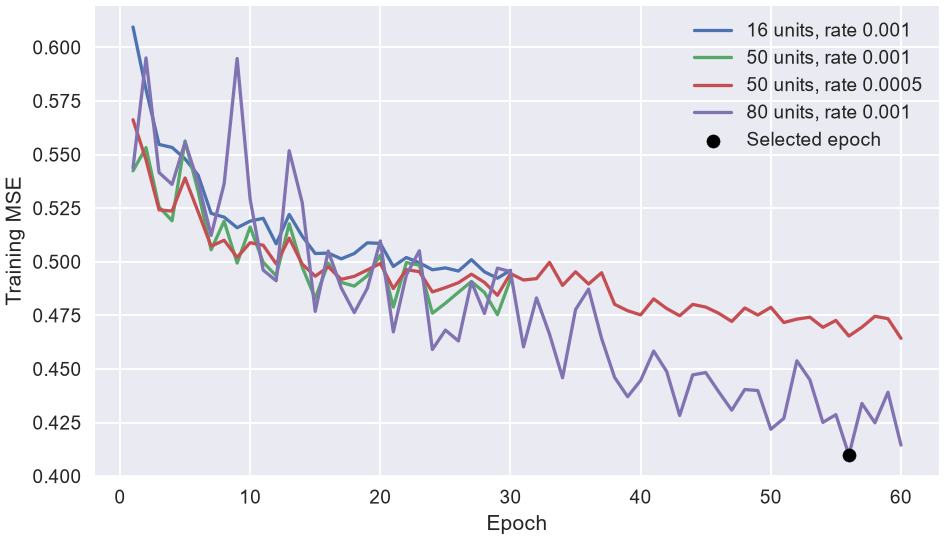

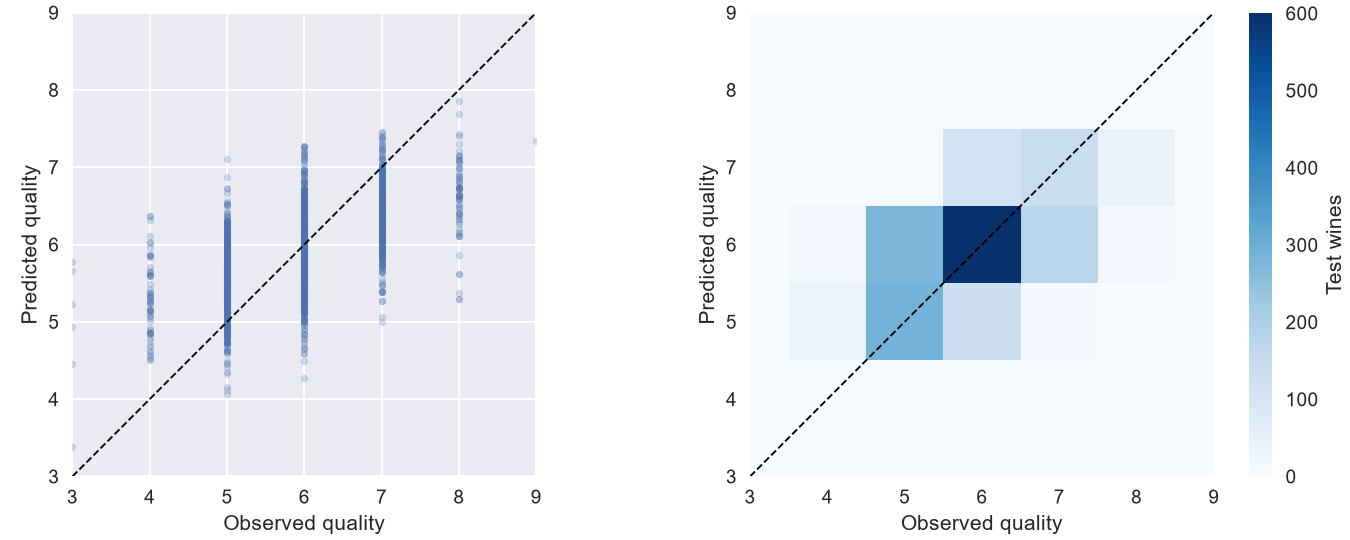

In [10]:
# Flatten the (n_test, 1) output so it aligns with the target vector.
predicted = dnn(X_test, *parameters).ravel()
test_mse = mse(predicted, y_test)
correlation = np.corrcoef(predicted, y_test)[0, 1]
# Compare with predicting the mean training quality for every test wine.
baseline = mse(y_train.mean(), y_test)
print(f"Selected configuration: {best_config}, checkpoint epoch {best_epoch}")
print(f"Train MSE: {train_losses.min():.4f}")
print(f"Test MSE: {test_mse:.4f}, RMSE: {np.sqrt(test_mse):.4f}")
print(f"Test Pearson r: {correlation:.4f}")
print(f"Training-mean baseline test MSE: {baseline:.4f}")

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for (width, rate, epochs), (losses, _, _) in runs.items():
    ax.plot(np.arange(1, epochs + 1), losses, label=f"{width} units, rate {rate:g}")
ax.scatter(best_epoch, train_losses.min(), color="black", zorder=3, label="Selected epoch")
ax.set(xlabel="Epoch", ylabel="Training MSE")
ax.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
bounds = [min(y_test.min(), predicted.min()), max(y_test.max(), predicted.max())]
axes[0].scatter(y_test, predicted, alpha=0.24, s=12)
# Center bins on integer quality ratings to show where predictions cluster.
bins = np.arange(2.5, 10.5, 1)
_, _, _, density = axes[1].hist2d(y_test, predicted, bins=[bins, bins], cmap="Blues")
fig.colorbar(density, ax=axes[1], label="Test wines")
# Draw the perfect-prediction line on both views.
for ax in axes:
    ax.plot(bounds, bounds, "k--", linewidth=1)
    ax.set(xlabel="Observed quality", ylabel="Predicted quality",
           xlim=bounds, ylim=bounds, aspect="equal")
plt.show()

# Conclusion: The best training MSE was 0.4098 at epoch 56 with
# 80 hidden units and a learning rate of 0.001. The test MSE was 0.5035
# (RMSE = 0.710, Pearson r = 0.594). This improved on the linear model
# (RMSE = 0.753), though the network still predicted mostly mid-range scores.

## Results

The lowest training MSE among the settings I tried was **0.4098**, at epoch 56 with 80 hidden units and a learning rate of 0.001. On the 1,898 test wines, the model reached an RMSE of **0.710 quality points** and a Pearson correlation of **0.594**. The linear model from Exercise 4.1 had a test RMSE of 0.753 on the same split. The scatter plot still shows predictions clustering around the middle scores.

# Hint 1

We want a network with one hidden layer. As activiation in the hidden layer $\sigma$ we apply element-wise ReLu, while no activation is used for the output layer. The forward pass of the network then reads:
$$\hat{y}=\mathbf{W}^{\prime} \sigma(\mathbf{W} \vec{x}+\vec{b})+b^{\prime}$$

# Hint 2

For the regression problem the objective function is the mean squared error between the prediction and the true label $y$:
$$
L=(\hat{y}-y)^{2}
$$

Taking the partial derivatives - and diligently the applying chain rule - with respect to the different objects yields:

$$
\begin{aligned}
\frac{\partial L}{\partial b^{\prime}} &=2(\hat{y}-y) \\
\frac{\partial L}{\partial b_{k}} &=2(\hat{y}-y) \mathbf{W}_{k}^{\prime} \theta\left(\sum_{i} \mathbf{W}_{k i} x_{i}+b_{k}\right) \\
\frac{\partial L}{\partial \mathbf{W}_{k}^{\prime}} &=2(\hat{y}-y) \sigma\left(\sum_{i} \mathbf{W}_{k i} x_{i}+b_{k}\right) \\
\frac{\partial L}{\partial \mathbf{W}_{m k}} &=2(\hat{y}-y) \mathbf{W}_{m}^{\prime} \theta\left(\sum_{i} \mathbf{W}_{m i} x_{i}+b_{m}\right) x_{k}
\end{aligned}
$$

Here, $\Theta$ denotes the Heaviside step function.